In [1]:
%pip install -q landingai pillow matplotlib gTTS

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
spacy 3.8.18 requires click<9.0.0,>=8.2.1, but you have click 8.1.8 which is incompatible.
xarray-einstats 0.11.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
wandb 0.28.1 requires click>=8.2.0, but you have click 8.1.8 which is incompatible.
jaxlib 0.11.1 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
ml-dtypes 0.6.0 requires numpy>=2.0.0, but you have numpy 1.26.4 which is incompatible.
ml-dtypes 0.6.0 requires numpy>=2.1.0; python_version >= "3.13", but you have numpy 1.26.4 which is incompatible.
opencv-contrib-python 4.14.0.94 requires numpy>=2; python_version >= "3.9", but you have nump

In [2]:
%pip install landingai

In [6]:
!pip install --upgrade --force-reinstall --no-cache-dir Pillow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 29.9 MB/s  0:00:00
  Attempting uninstall: Pillow
    Found existing installation: pillow 10.4.0
    Uninstalling pillow-10.4.0:
      Successfully uninstalled pillow-10.4.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
landingai 0.3.49 requires pillow<11.0,>=9.0, but you have pillow 13.0.0 which is incompatible.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [1]:
import PIL
print("Pillow version:", PIL.__version__)

Pillow version: 13.0.0


In [2]:
import io
import PIL
from PIL import Image

print("Pillow version:", PIL.__version__)

# Test Pillow's JPEG encoder independently of LandingAI
buffer = io.BytesIO()
test_image = Image.new("RGB", (10, 10), color="red")
test_image.save(buffer, format="JPEG")

print("JPEG encoding successful:", len(buffer.getvalue()), "bytes")

Pillow version: 13.0.0
JPEG encoding successful: 633 bytes


In [3]:
from google.colab import userdata
from landingai.predict import Predictor

API_KEY = userdata.get("ucs420_ass9")

ENDPOINT_ID = "c7884cfd-e59f-49eb-bdbe-1345cb90fc5f"

predictor = Predictor(
    endpoint_id=ENDPOINT_ID,
    api_key=API_KEY
)

print("Cognitive Assistant Connected!")

Cognitive Assistant Connected!


In [4]:

from google.colab import files
from PIL import Image
import io
import numpy as np

uploaded = files.upload()
filename = next(iter(uploaded))

with Image.open(io.BytesIO(uploaded[filename])) as im:
    image = im.convert("RGB").copy()

image_array = np.array(image)

print("Image size:", image.size)
print("Image array shape:", image_array.shape)


Saving sambhav.JPG to sambhav.JPG
Image size: (1600, 1200)
Image array shape: (1200, 1600, 3)


In [5]:

predictions = predictor.predict(image_array)

print("Prediction count:", len(predictions))

for i, prediction in enumerate(predictions, start=1):
    print(f"\nPrediction {i}:")
    print(prediction)


Prediction count: 1

Prediction 1:
score=0.949270486831665 label_name='Sambhav' label_index=1 id='e97628cc-280f-403e-b68f-1f947ae5a702' bboxes=(715, 590, 1031, 1000)


Wildfire Cognitive Assistant
Upload an image for analysis.


Saving download.jpeg to download.jpeg


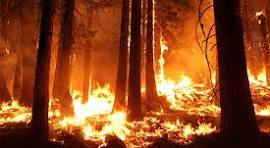


Raw model predictions:
[]
No predictions returned by the model.


In [6]:

from google.colab import files
from PIL import Image
from IPython.display import display, Markdown, Audio
from gtts import gTTS
import numpy as np
import io

def wildfire_assistant():

    print("Wildfire Cognitive Assistant")
    print("Upload an image for analysis.")

    # 1. Upload image
    uploaded = files.upload()
    if not uploaded:
        print("No image uploaded.")
        return

    filename = next(iter(uploaded))

    with Image.open(io.BytesIO(uploaded[filename])) as img:
        image = img.convert("RGB").copy()

    display(image)

    # 2. Run the connected LandingAI model
    predictions = predictor.predict(np.array(image))

    print("\nRaw model predictions:")
    print(predictions)

    if not predictions:
        print("No predictions returned by the model.")
        return

    # 3. Read the ClassificationPrediction object
    prediction = predictions[0]

    predicted_label = getattr(prediction, "label_name", None)
    predicted_index = getattr(prediction, "label_index", None)
    confidence = getattr(prediction, "score", None)

    print("Predicted label:", predicted_label)
    print("Predicted class index:", predicted_index)
    print("Confidence:", confidence)

    # 4. Interpret the model's class index
    # Assumption: index 1 = Fire, index 0 = No Fire
    if predicted_index == 1:
        result = "Fire! Fire!"
        print("🔥 FIRE DETECTED!")
    elif predicted_index == 0:
        result = "Safe"
        print("No-fire class predicted.")
    else:
        result = "Unable to determine"
        print("Unknown class index.")

    display(Markdown(f"### Assistant response: **{result}**"))

    # 5. Generate audio response
    if result != "Unable to determine":
        speech = gTTS(text=result, lang="en")
        speech.save("wildfire_response.mp3")

        display(Audio("wildfire_response.mp3", autoplay=False))
        files.download("wildfire_response.mp3")


wildfire_assistant()
